<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report : Shooting method to solve the Blasius equation**

**Submitted By ,**  

**Aathi Skantha Roopan T - SC26M001**


# Required packages

In [1]:
# do not change line below
from google.colab import files
# import required packages here
import numpy as np
import matplotlib.pyplot as plt

# Problem statement

This assignment requires solving the Blasius boundary value problem (BVP) using the Shooting Method, with both RK3 and RK4 numerical integration.

# Governing Equation

The Blasius equation is
$$f'''+\frac{1}{2}ff''=0$$

Boundary conditions:

$$f(0)=0 \qquad f'(0)=0$$

$$f'(\infty)=1$$


Since we cannot numerically integrate up to infinity, we choose a sufficiently large value, for example,

${\eta_\infty=10}$


# (a) & (b) Converting into first order System and Introduce shooting parameter

Define

$$Y_1=f \quad Y_2=f'\quad Y_3=f''$$


Differentiating,

$$Y_1'=Y_2$$
$$
Y_2'=Y_3
$$

From the Blasius equation,

$$Y_3'=-\frac{1}{2}Y_1Y_3$$

Therefore,

$$
\frac{dY}{d\eta}=\begin{bmatrix}Y_2\\Y_3\\-\frac12Y_1Y_3\end{bmatrix}
$$


Initial conditions:

$$Y_1(0)=0 \qquad Y_2(0)=0$$

The missing initial condition is
$$
\boxed{Y_3(0)=s=f''(0)}
$$

This is our shooting parameter.

In [2]:
def blasius(eta, Y):

    f = Y[0]
    fp = Y[1]
    fpp = Y[2]

    dY1 = fp
    dY2 = fpp
    dY3 = -0.5 * f * fpp

    return np.array([dY1, dY2, dY3])

Here:
- Y[0] represents \(f\).
- Y[1] represents \(f'\).
- Y[2] represents \(f''\).

The function returns the derivatives at a particular value of $(\eta)$

# (c) & (d) Defining Residual Solution and RK3

We use the classical third-order Runge-Kutta method

$$k_1=G(Y_n)$$  

$$k_2=G\left(Y_n+\frac h2k_1\right)$$

$$k_3=G(Y_n-hk_1+2hk_2)$$

$$Y_{n+1}=Y_n+\frac h6(k_1+4k_2+k_3)$$

In [3]:
def rk3_step(eta, Y, h):

    k1 = blasius(eta, Y)

    k2 = blasius(eta + h/2,Y + (h/2)*k1)

    k3 = blasius(eta + h,Y - h*k1 + 2*h*k2)

    Y_new = Y + (h/6)*(k1 + 4*k2 + k3)

    return Y_new

**Integrate using RK3**

This function integrates the equations from $\eta$=0 to $\eta$=10 for a given shooting parameter.

In [4]:
eta_inf = 10.0
def integrate_rk3(s, h):

    n = int(round(eta_inf / h))

    eta = np.linspace(0, eta_inf, n + 1)

    Y = np.zeros((n + 1, 3))

    Y[0] = [0, 0, s]

    for i in range(n):

        Y[i+1] = rk3_step(eta[i], Y[i], h)

    return eta, Y

**Define the residual function**

The required boundary condition is:
$$
f'(\eta_\infty)=1
$$

Therefore, the residual is:
$$
\boxed{F(s)=f'(10;s)-1}
$$

In [5]:
def residual_rk3(s, h):

    eta, Y = integrate_rk3(s, h)

    return Y[-1, 1] - 1

**Implement the bisection method**

The bisection method finds the root of the residual function.

We initially choose:

$$s_L=0.3 \qquad s_U=0.4$$

According to the Intermediate Value Theorem, if the residual is continuous and its values at the two endpoints have opposite signs, at least one root exists between them.

1.Check the lower guess: $s_L=0.3$  

Using RK integration, calculate:
$$
F(0.3)=f'(10;0.3)-1
$$

The numerical result is approximately:
$$
\boxed{F(0.3)\approx-0.092}
$$

This means the calculated velocity at $\eta$=10 is less than 1.

2.Check the upper guess: $s_U=0.4$  

Similarly,
$$
F(0.4)=f'(10;0.4)-1
$$

The numerical result is approximately:
$$
\boxed{F(0.4)\approx+0.18}
$$

This means the calculated velocity at $\eta$=10 is greater than 1.

Therefore,
$$
F(0.3)\times F(0.4)<0
$$

Hence, a root exists between 0.3 and 0.4.
$$
\boxed{0.3<s<0.4}
$$

In [6]:
h = 0.1

s_lower = 0.3
s_upper = 0.4

F_lower = residual_rk3(s_lower, h)
F_upper = residual_rk3(s_upper, h)

print("F(0.3) =", F_lower)
print("F(0.4) =", F_upper)

if F_lower * F_upper < 0:
    print("Root exists between 0.3 and 0.4")
else:
    print("Choose another interval")

F(0.3) = -0.0654423962078492
F(0.4) = 0.13213651172221774
Root exists between 0.3 and 0.4


In [7]:
def bisection(func, a, b, h, tol=1e-10):

    fa = func(a, h)
    fb = func(b, h)

    if fa * fb > 0:
        raise ValueError("Root is not bracketed.")

    while abs(b - a) > tol:

        c = (a + b) / 2

        fc = func(c, h)

        if fa * fc < 0:

            b = c
            fb = fc

        else:

            a = c
            fa = fc

    return (a + b) / 2

**Calculate the shooting parameter for RK3**

In [8]:
step_sizes = [0.4, 0.2, 0.1, 0.05, 0.025]
tolerance = 1e-10
rk3_results = []

for h in step_sizes:

    s = bisection(residual_rk3, 0.3, 0.4, h, tolerance)

    rk3_results.append(s)

    print("Step size =", h, " Shooting parameter =", s)

Step size = 0.4  Shooting parameter = 0.33197714476846146
Step size = 0.2  Shooting parameter = 0.3320495982188731
Step size = 0.1  Shooting parameter = 0.3320565334055573
Step size = 0.05  Shooting parameter = 0.3320572476368397
Step size = 0.025  Shooting parameter = 0.33205732670612637


**Obtain the final RK3 solution**  

For plotting, use the smallest step size 0.025

In [9]:
h = 0.025

s_rk3 = bisection(residual_rk3, 0.3, 0.4, h, tolerance)

eta_rk3, Y_rk3 = integrate_rk3(s_rk3, h)

print("RK3 shooting parameter =", s_rk3)

RK3 shooting parameter = 0.33205732670612637


**Plot RK3 velocity profiles**

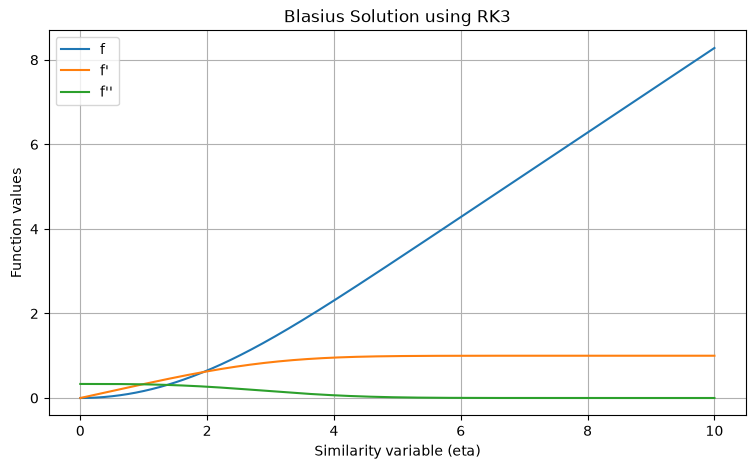

In [10]:
plt.figure(figsize=(9, 5))

plt.plot(eta_rk3, Y_rk3[:, 0], label="f")
plt.plot(eta_rk3, Y_rk3[:, 1], label="f'")
plt.plot(eta_rk3, Y_rk3[:, 2], label="f''")

plt.xlabel("Similarity variable (eta)")
plt.ylabel("Function values")

plt.title("Blasius Solution using RK3")
plt.legend()
plt.grid()
plt.show()

**Solution using RK4**

Define the fourth-order Runge-Kutta method

$$
k_1=G(Y_n)
$$
$$
k_2=G\left(Y_n+\frac h2k_1\right)
$$

$$
k_3=G\left(Y_n+\frac h2k_2\right)
$$
$$
k_4=G(Y_n+hk_3)
$$

The updated solution is:  

$$
\boxed{Y_{n+1}=Y_n+\frac h6(k_1+2k_2+2k_3+k_4)}
$$

In [11]:
def rk4_step(eta, Y, h):

    k1 = blasius(eta, Y)

    k2 = blasius(eta + h/2,Y + (h/2)*k1)

    k3 = blasius(eta + h/2,Y + (h/2)*k2)

    k4 = blasius(eta + h,Y + h*k3)

    Y_new = Y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return Y_new
    

**Integrate using RK4**

In [12]:
def integrate_rk4(s, h):

    n = int(round(eta_inf / h))

    eta = np.linspace(0, eta_inf, n + 1)

    Y = np.zeros((n + 1, 3))

    Y[0] = [0, 0, s]

    for i in range(n):

        Y[i+1] = rk4_step(eta[i], Y[i], h)

    return eta, Y

**Define the RK4 residual function**

$$
F(s)=f'(10;s)-1
$$

In [13]:
def residual_rk4(s, h):

    eta, Y = integrate_rk4(s, h)

    return Y[-1, 1] - 1

**Calculate the shooting parameter for RK4**

We use the same bisection method

In [14]:
step_sizes = [0.4, 0.2, 0.1, 0.05, 0.025]
tolerance = 1e-10
rk4_results = []

for h in step_sizes:

    s = bisection(residual_rk4, 0.3, 0.4, h, tolerance)

    rk4_results.append(s)

    print("Step size =", h, " Shooting parameter =", s)

Step size = 0.4  Shooting parameter = 0.33205881579779084
Step size = 0.2  Shooting parameter = 0.33205745746381576
Step size = 0.1  Shooting parameter = 0.3320573456119746
Step size = 0.05  Shooting parameter = 0.33205733778886487
Step size = 0.025  Shooting parameter = 0.33205733723007136


**Obtain the final RK4 solution**

In [15]:
h = 0.025

s_rk4 = bisection(residual_rk4, 0.3, 0.4, h, tolerance)

eta_rk4, Y_rk4 = integrate_rk4(s_rk4, h)

print("RK4 shooting parameter =", s_rk4)

RK4 shooting parameter = 0.33205733723007136


**Plot RK4 velocity profiles**

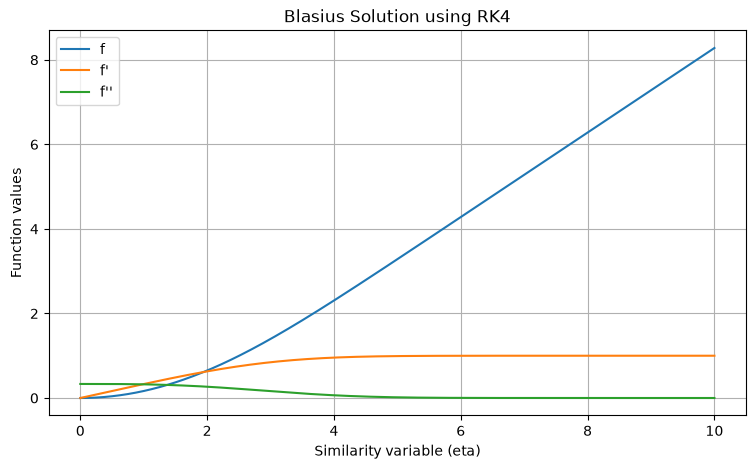

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(eta_rk4, Y_rk4[:, 0], label="f")
plt.plot(eta_rk4, Y_rk4[:, 1], label="f'")
plt.plot(eta_rk4, Y_rk4[:, 2], label="f''")

plt.xlabel("Similarity variable (eta)")
plt.ylabel("Function values")
plt.title("Blasius Solution using RK4")
plt.legend()
plt.grid()
plt.show()

# Convergence and order of accuracy

The accepted Blasius value is:  
$$
s_{\text{exact}}=0.332057336215
$$
The absolute error is:  
$$
\boxed{E=|s_{\text{numerical}}-s_{\text{exact}}|}
$$

In [17]:
s_exact = 0.332057336215

rk3_errors = np.abs(np.array(rk3_results) - s_exact)

rk4_errors = np.abs(np.array(rk4_results) - s_exact)

**Create convergence tables**

In [18]:
print("RK3 RESULTS")
print("---------------------------------------------")
print("Step size       Shooting parameter    Error")

for i in range(len(step_sizes)):

    print(f"{step_sizes[i]:.5f}       "
          f"{rk3_results[i]:.12f}       "
          f"{rk3_errors[i]:.6e}")


print("\nRK4 RESULTS")
print("---------------------------------------------")
print("Step size       Shooting parameter    Error")

for i in range(len(step_sizes)):

    print(f"{step_sizes[i]:.5f}       "
          f"{rk4_results[i]:.12f}       "
          f"{rk4_errors[i]:.6e}")

RK3 RESULTS
---------------------------------------------
Step size       Shooting parameter    Error
0.40000       0.331977144768       8.019145e-05
0.20000       0.332049598219       7.737996e-06
0.10000       0.332056533406       8.028094e-07
0.05000       0.332057247637       8.857816e-08
0.02500       0.332057326706       9.508874e-09

RK4 RESULTS
---------------------------------------------
Step size       Shooting parameter    Error
0.40000       0.332058815798       1.479583e-06
0.20000       0.332057457464       1.212488e-07
0.10000       0.332057345612       9.396975e-09
0.05000       0.332057337789       1.573865e-09
0.02500       0.332057337230       1.015071e-09


**Calculate the observed order of accuracy**

The order of accuracy is calculated using:
$$
\boxed{
p=\frac{\log(E_1/E_2)}{\log(h_1/h_2)}
}
$$

Since each step size is half the previous one:
$$
p=\frac{\log(E_1/E_2)}{\log(2)}
$$

In [19]:
rk3_order = []

rk4_order = []

for i in range(len(step_sizes)-1):

    p3 = np.log(rk3_errors[i] / rk3_errors[i+1]) / np.log(2)

    p4 = np.log(rk4_errors[i] / rk4_errors[i+1]) / np.log(2)

    rk3_order.append(p3)

    rk4_order.append(p4)


print("Observed order of accuracy")
print("--------------------------------------")
print("Step size       RK3 order       RK4 order")

for i in range(len(rk3_order)):

    print(f"{step_sizes[i]:.5f}       "
          f"{rk3_order[i]:.4f}       "
          f"{rk4_order[i]:.4f}")

Observed order of accuracy
--------------------------------------
Step size       RK3 order       RK4 order
0.40000       3.3734       3.6091
0.20000       3.2688       3.6896
0.10000       3.1800       2.5779
0.05000       3.2196       0.6327


**Plot the log-log convergence graph**

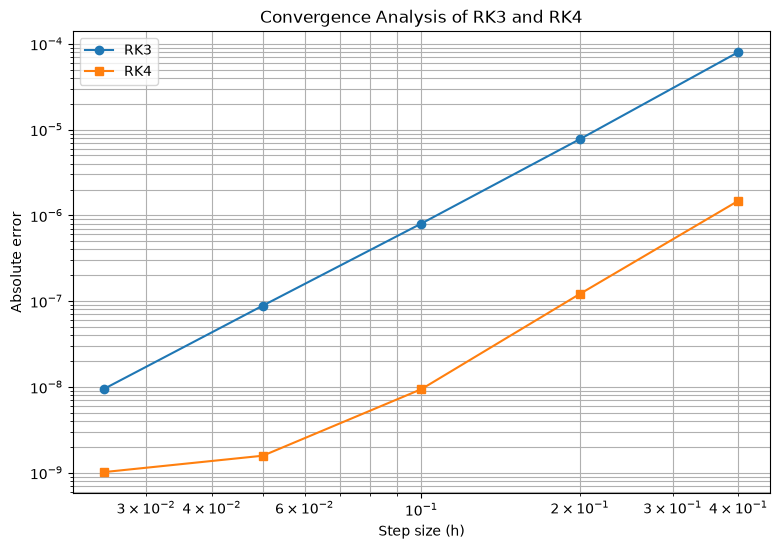

In [20]:
plt.figure(figsize=(9, 6))
plt.loglog(step_sizes, rk3_errors, 'o-', label="RK3")
plt.loglog(step_sizes, rk4_errors, 's-', label="RK4")
plt.xlabel("Step size (h)")
plt.ylabel("Absolute error")
plt.title("Convergence Analysis of RK3 and RK4")
plt.legend()
plt.grid(True, which="both")
plt.show()

**Display the final shooting parameters**

In [21]:
print("FINAL RESULTS")
print("==============================")

print("Accepted value =", s_exact)

print("\nRK3 result:")
print("f''(0) =", s_rk3)
print("Error =", abs(s_rk3 - s_exact))

print("\nRK4 result:")
print("f''(0) =", s_rk4)
print("Error =", abs(s_rk4 - s_exact))

FINAL RESULTS
Accepted value = 0.332057336215

RK3 result:
f''(0) = 0.33205732670612637
Error = 9.508873632935178e-09

RK4 result:
f''(0) = 0.33205733723007136
Error = 1.0150713602996575e-09


Both results approach:
$$
\boxed{f''(0)=0.332057}
$$

# Conclusion

The Blasius boundary value problem was successfully solved using the shooting method with RK3 and RK4 numerical integration schemes. The unknown initial condition was determined using the bisection method. The velocity profiles were obtained and the convergence behaviour was studied using a log-log plot. The results agree with the accepted Blasius solution, with $$f''(0)\approx 0.332\$$ The comparison confirms the higher-order accuracy of RK4 compared with RK3.